### **Koneksi Neo4j**

In [2]:
from neo4j import GraphDatabase
import getpass

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "Shellatiwi123"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="neo4j")

### **Cek file Events.csv**

In [4]:
import os

csv_file_path = os.path.join("dataset", "events.csv")

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"Error: File '{csv_file_path}' tidak ditemukan!"
    )

print(f"File ditemukan: {csv_file_path}")

File ditemukan: dataset\events.csv


### **Rentang Waktu**

In [5]:
import pandas as pd

df = pd.read_csv("dataset/events.csv")
df["date"] = pd.to_datetime(df["timestamp"], unit="ms")

p1 = df[(df["date"] >= "2015-08-01") & (df["date"] < "2015-08-17")]
p2 = df[(df["date"] >= "2015-08-17") & (df["date"] < "2015-08-21")]

n = len(p1) + len(p2)
print("Baris:", len(p1), len(p2), f"-> {len(p1)/n:.1%} / {len(p2)/n:.1%}")
print("Transaksi:", (p1["event"] == "transaction").sum(), (p2["event"] == "transaction").sum())

v1, v2 = set(p1["visitorid"]), set(p2["visitorid"])
print("Visitor:", len(v1), len(v2), "| Irisan:", len(v1 & v2))

# irisan yang punya transaksi di P2 (kandidat user untuk 2.2)
kandidat = set(p2.loc[p2["event"] == "transaction", "visitorid"]) & v1
print("Kandidat user (ada di P1 + beli di P2):", len(kandidat))

Baris: 280001 80912 -> 77.6% / 22.4%
Transaksi: 2169 837
Visitor: 162337 47074 | Irisan: 3318
Kandidat user (ada di P1 + beli di P2): 67


In [6]:
p1.drop(columns="date").to_csv("dataset/events_p1.csv", index=False)
p2.drop(columns="date").to_csv("dataset/events_p2.csv", index=False)
print(len(p1), len(p2))

280001 80912


### **Import dataset ke Neo4j**

In [8]:
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Shellatiwi123")
csv_file_path = "dataset/events_p1.csv"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    tx.run("""
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp,
                             transactionId: row.transactionid}]->(i))
    """, batch=batch)

batch_size = 5000
total_rows = 280001
total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        session.execute_write(import_batch, chunk.to_dict(orient="records"))

print("Proses impor selesai")

Mengimpor Batch Data: 100%|██████████| 57/57 [03:18<00:00,  3.49s/it]

Proses impor selesai


# SOAL UTS 2.1 Wrangling dan EDA

Soal No.1 Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak
boleh sama dalam 1 kelas. 

Fold training (P1) →  1 - 16 Agustus 2015
Fold testing (P2) →  17 - 20 Agustus 2015

Soal No.3

In [9]:
with driver.session(database="neo4j") as session:
    print("Simpul:")
    for r in session.run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah"):
        print(" ", r["label"], r["jumlah"])
    print("Relasi:")
    for r in session.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"):
        print(" ", r["relasi"], r["jumlah"])

Simpul:
  Visitor 162337
  Item 78365
Relasi:
  VIEWED 270404
  ADDED_TO_CART 7428
  BOUGHT 2169


Berdasarkan hasil query Python API, subgraph training P1 (1–16 Agustus 2015) memiliki 240.702 simpul dan 280.001 relasi.

- Simpul: Visitor sebanyak 162.337 dan Item sebanyak 78.365.
- Relasi: VIEWED sebanyak 270.404, ADDED_TO_CART sebanyak 7.428, dan BOUGHT sebanyak 2.169.

Query Cypher MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah digunakan untuk menghitung jumlah simpul berdasarkan labelnya. Sementara itu, MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah digunakan untuk menghitung jumlah relasi berdasarkan tipenya. Hasil query ditampilkan melalui Python API menggunakan session.run().

Soal No.4 dan 5: bangun matriks dari Neo4j

In [10]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

query = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH v, i, max(CASE type(r)
    WHEN 'VIEWED' THEN 1
    WHEN 'ADDED_TO_CART' THEN 3
    WHEN 'BOUGHT' THEN 5 END) AS w
RETURN v.visitorId AS u, i.itemId AS it, w
"""
with driver.session(database="neo4j") as session:
    pairs = pd.DataFrame(session.run(query).data())

u_cat = pairs["u"].astype("category")
i_cat = pairs["it"].astype("category")

A = csr_matrix((pairs["w"], (u_cat.cat.codes, i_cat.cat.codes)),
               shape=(len(u_cat.cat.categories), len(i_cat.cat.categories)))

print("Pasangan unik:", len(pairs), "dari 280001 relasi")
print("Matriks User x Item:", A.shape, "| nnz:", A.nnz)
print(f"Density: {A.nnz / (A.shape[0] * A.shape[1]):.6%}")

u_deg = np.diff(A.indptr)               
i_deg = np.diff(A.tocsc().indptr)      
print("Item per visitor:\n", pd.Series(u_deg).describe())
print("Visitor per item:\n", pd.Series(i_deg).describe())

# Batas atas jumlah pasangan pada proyeksi (untuk nomor 6)
print("Proyeksi User-User (batas atas):", int((i_deg * (i_deg - 1) // 2).sum()))
print("Proyeksi Item-Item (batas atas):", int((u_deg * (u_deg - 1) // 2).sum()))

Pasangan unik: 224732 dari 280001 relasi
Matriks User x Item: (162337, 78365) | nnz: 224732
Density: 0.001767%
Item per visitor:
 count    162337.000000
mean          1.384355
std           4.154412
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         910.000000
dtype: float64
Visitor per item:
 count    78365.000000
mean         2.867760
std          7.423326
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       1402.000000
dtype: float64
Proyeksi User-User (batas atas): 2369027
Proyeksi Item-Item (batas atas): 1444078


No. 4: Vector Space Modelling (User)

VSM terhadap simpul User direpresentasikan menggunakan matriks User × Item dengan ukuran (162337, 78365). Matriks memiliki 162.337 baris yang mewakili Visitor dan 78.365 kolom yang mewakili Item.

Jumlah elemen tidak nol (NNZ) adalah 224.732 dengan kepadatan (density) sebesar 0,001767%. Hal ini menunjukkan bahwa matriks bersifat sangat sparse karena sebagian besar Visitor hanya berinteraksi dengan sebagian kecil Item.

Setiap baris merepresentasikan pola interaksi seorang Visitor terhadap berbagai Item. Matriks sparse digunakan agar penyimpanan dan pengolahan data lebih efisien.

In [ ]:
S_item = (A.T @ A)         
S_user = (A @ A.T)          
print("Item-Item nonzero (tanpa diagonal):", S_item.nnz - A.shape[1])
print("User-User nonzero (tanpa diagonal):", S_user.nnz - A.shape[0])

Item-Item nonzero (tanpa diagonal): 2781690
User-User nonzero (tanpa diagonal): 4666546


Berdasarkan hasil perhitungan matriks, proyeksi Item–Item memiliki 2.781.690 elemen tidak nol (nonzero), sedangkan proyeksi User–User memiliki 4.666.546 elemen tidak nol, keduanya tanpa diagonal.

Hasil tersebut menunjukkan bahwa proyeksi User–User menghasilkan lebih banyak hubungan dibandingkan proyeksi Item–Item. Namun, jumlah hubungan yang lebih sedikit pada proyeksi Item–Item berpotensi membuat proses komputasi lebih efisien.

### plot networkx (sampel kecil) 15 visitor

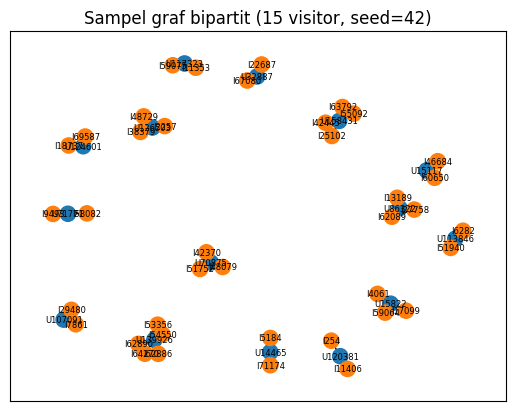

In [12]:
import networkx as nx
import matplotlib.pyplot as plt

# Sampel: 15 visitor dengan >=2 item (agar terlihat strukturnya), reproducible
rng = np.random.default_rng(42)
kand = np.where(u_deg >= 2)[0]
pilih = rng.choice(kand, size=15, replace=False)

G = nx.Graph()
sub = A[pilih]
for r, u_idx in enumerate(pilih):
    row = sub.getrow(r)
    for i_idx, w in zip(row.indices, row.data):
        G.add_edge(f"U{u_idx}", f"I{i_idx}", weight=w)

warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]
nx.draw_networkx(G, node_color=warna, node_size=120, font_size=6)
plt.title("Sampel graf bipartit (15 visitor, seed=42)")
plt.show()

graf bipartit yang terdiri dari simpul Visitor berwarna biru dan Item berwarna oranye. Garis menunjukkan hubungan interaksi antara Visitor dan Item. Pada gambar ini, label simpul terlihat bertumpuk sehingga hubungan cukup sulit diamati.

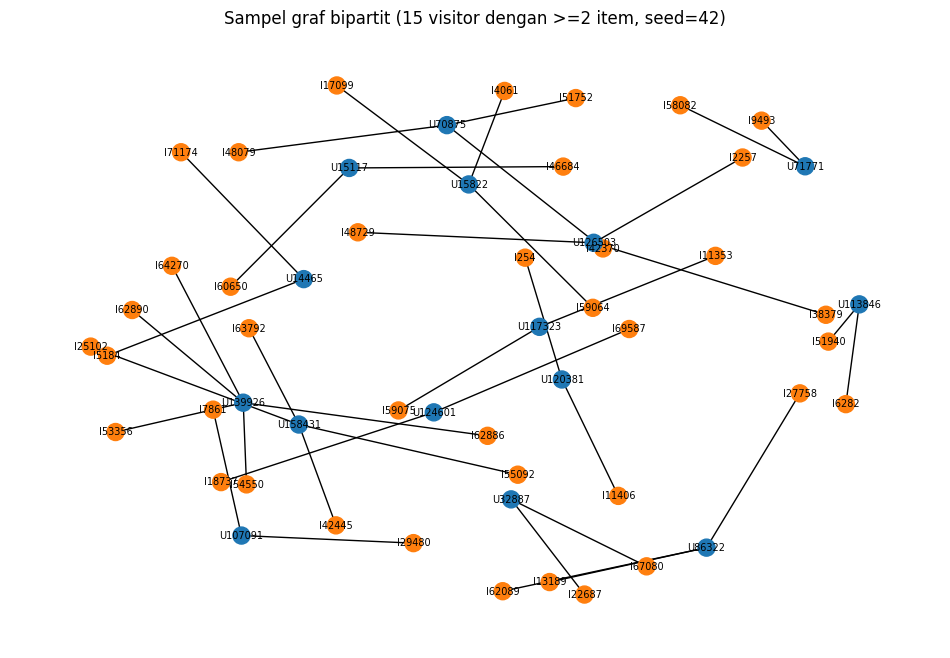

In [13]:
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42, k=0.6)
nx.draw_networkx(G, pos, node_color=warna, node_size=150, font_size=7)
plt.title("Sampel graf bipartit (15 visitor dengan >=2 item, seed=42)")
plt.axis("off")
plt.show()

sampel terpotong (maks 25 visitor per item), bukan seluruh graf. graf bipartit dengan posisi simpul yang lebih menyebar. Hubungan antara Visitor dan Item terlihat lebih jelas, sehingga pola interaksi antarsimpul lebih mudah diamati.

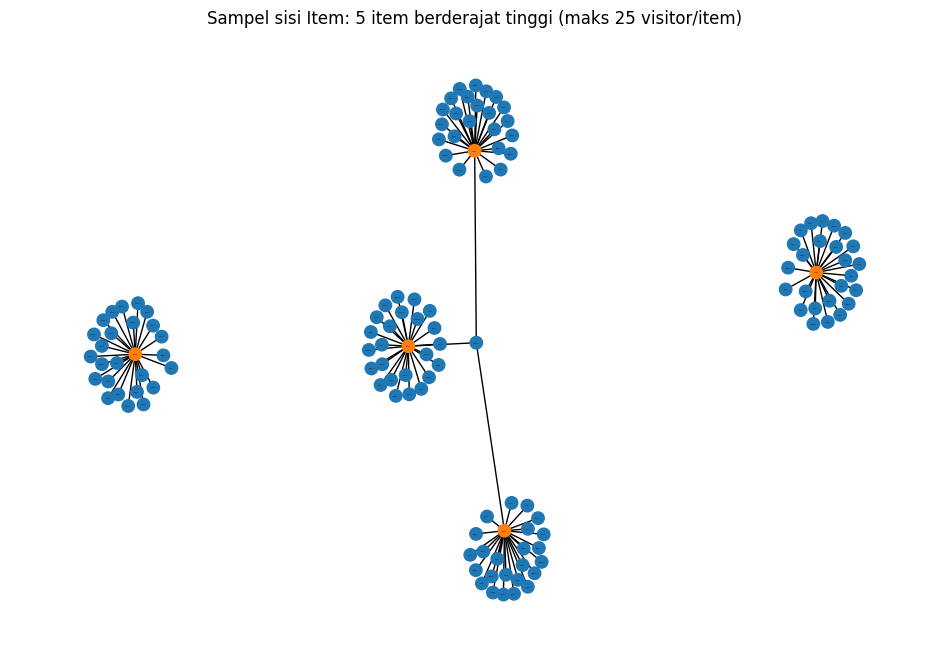

In [ ]:
i_deg_arr = np.array(i_deg)
top_items = np.argsort(-i_deg_arr)[10:15]   
Gi = nx.Graph()
At = A.T.tocsr()
for it in top_items:
    row = At.getrow(it)
    for u_idx in row.indices[:25]:           
        Gi.add_edge(f"I{it}", f"U{u_idx}")
warna_i = ["tab:orange" if n.startswith("I") else "tab:blue" for n in Gi.nodes]
plt.figure(figsize=(12, 8))
nx.draw_networkx(Gi, node_color=warna_i, node_size=80, font_size=0)
plt.title("Sampel sisi Item: 5 item berderajat tinggi (maks 25 visitor/item)")
plt.axis("off"); plt.show()

Sampel 5 item berderajat tinggi (peringkat 10-14 menurut jumlah visitor,
maks 25 visitor per item, bukan seluruh graf). Tiap item membentuk gugus
bintang dengan banyak visitor, dan satu visitor menjembatani tiga item.
Ini kontras dengan sisi User yang terpecah menjadi komponen kecil, dan
konsisten dengan angka: rata-rata 2,87 visitor per item vs 1,38 item
per visitor.

Soal No.5 Vector Space Modelling (VSM) Simpul Item

VSM terhadap simpul Item direpresentasikan menggunakan matriks User × Item berukuran (162.337, 78.365). Setiap kolom merepresentasikan satu Item, sedangkan setiap baris merepresentasikan Visitor yang berinteraksi dengan Item tersebut.

| Karakteristik | Nilai |
|---|---|
| Shape matriks Item x User | 78.365 x 162.337 |
| Dimensi vektor tiap Item | 162.337 |
| nnz / density | 224.732 / 0,001767% (sama, hanya transpos) |
| Visitor per item | median 1, persentil 75 = 3, rata-rata 2,87, maks 1.402 |

Berdasarkan hasil perhitungan, jumlah Visitor per Item memiliki rata-rata 2,87, median 1, dan nilai maksimum 1.402. Hal ini menunjukkan bahwa sebagian besar Item hanya berinteraksi dengan sedikit Visitor, sedangkan beberapa Item memiliki jumlah interaksi yang jauh lebih tinggi. Pada proyeksi Item–Item, terdapat 2.781.690 elemen tidak nol tanpa diagonal. Proyeksi ini menggambarkan hubungan kemiripan antar-Item berdasarkan pola interaksi Visitor.

No. 6: Perbandingan Proyeksi

| | User-User | Item-Item |
|---|---|---|
| Jumlah simpul | 162.337 | 78.365 |
| Pasangan unik (relasi nyata ÷ 2) | 2.333.273 | 1.390.845 |

Kesimpulan: Proyeksi Item–Item lebih baik dari segi efisiensi komputasi karena memiliki jumlah simpul sekitar 2,07 kali lebih sedikit dan pasangan unik sekitar 1,68 kali lebih sedikit dibandingkan proyeksi User–User.

Dari segi efektivitas, sebagian besar Visitor hanya berinteraksi dengan sedikit Item. Sebanyak 75% Visitor berinteraksi dengan paling banyak satu Item berdasarkan hasil statistik sebelumnya, sehingga kemiripan antar-Visitor cenderung sulit diperoleh. Sebaliknya, proyeksi Item–Item memungkinkan kemiripan antar-Item dilihat berdasarkan kesamaan Visitor yang berinteraksi dengannya.

Namun, keunggulan efektivitas tersebut masih berupa dugaan berdasarkan karakteristik data. Penentuan proyeksi yang paling efektif perlu dikonfirmasi melalui evaluasi rekomendasi menggunakan metrik Hit@5 dan NDCG@5 pada tahap berikutnya.

In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix


train_ref = pd.read_csv("dataset/events_p1.csv")

# Bobot berdasarkan jenis interaksi
WEIGHTS = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

train_ref["weight"] = train_ref["event"].map(WEIGHTS)
train_ref = train_ref.dropna(subset=["weight"])

# Agregasi bobot interaksi pengunjung-item
user_item_ref = (
    train_ref.groupby(["visitorid", "itemid"])["weight"]
    .sum()
    .reset_index()
)

visitor_ids_ref = user_item_ref["visitorid"].unique()
item_ids_ref = user_item_ref["itemid"].unique()

visitor_index_ref = {
    visitor_id: idx
    for idx, visitor_id in enumerate(visitor_ids_ref)
}

item_index_ref = {
    item_id: idx
    for idx, item_id in enumerate(item_ids_ref)
}

X_user_ref = csr_matrix(
    (
        user_item_ref["weight"].to_numpy(),
        (
            user_item_ref["visitorid"].map(visitor_index_ref).to_numpy(),
            user_item_ref["itemid"].map(item_index_ref).to_numpy()
        )
    ),
    shape=(len(visitor_ids_ref), len(item_ids_ref))
)

X_item_ref = X_user_ref.T.tocsr()

print("VSM Visitor:", X_user_ref.shape)
print("VSM Item:", X_item_ref.shape)
print("Jumlah interaksi unik berbobot:", X_user_ref.nnz)

VSM Visitor: (162337, 78365)
VSM Item: (78365, 162337)
Jumlah interaksi unik berbobot: 224732


In [16]:
from sklearn.neighbors import NearestNeighbors

# Pilih item referensi pertama secara konsisten
reference_index_ref = 0
reference_item_ref = int(item_ids_ref[reference_index_ref])

knn_item_ref = NearestNeighbors(
    n_neighbors=min(6, X_item_ref.shape[0]),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn_item_ref.fit(X_item_ref)

distances_ref, indices_ref = knn_item_ref.kneighbors(
    X_item_ref[reference_index_ref],
    n_neighbors=min(6, X_item_ref.shape[0])
)

similarity_rows_ref = []

for idx, distance in zip(indices_ref[0], distances_ref[0]):
    similar_item = int(item_ids_ref[idx])

    if similar_item == reference_item_ref:
        continue

    similarity_rows_ref.append({
        "reference_item_id": reference_item_ref,
        "similar_item_id": similar_item,
        "cosine_similarity": float(1 - distance)
    })

top5_similarity_ref = (
    pd.DataFrame(similarity_rows_ref)
    .sort_values("cosine_similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(top5_similarity_ref)

,reference_item_id,similar_item_id,cosine_similarity
0,72028,276885,0.298142
1,72028,192013,0.288675
2,72028,169233,0.218218
3,72028,323403,0.193649
4,72028,42210,0.192450


In [17]:
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH (i:Item)<-[r]-(v:Visitor)
        WITH i, count(DISTINCT v) AS n
        WHERE n >= 20 AND n <= 100
        RETURN i.itemId AS item, n ORDER BY n DESC LIMIT 10
    """)
    for r in hasil:
        print(r["item"], r["n"])

142466 99
453618 98
69533 97
546 92
66752 92
29100 92
247909 91
345279 89
158666 89
298009 88


### Soal No. 7a Menghitung dan menyimpan 5 item paling mirip (Cosine Similarity)

In [21]:
similarity_records_ref = [
    {
        "item": int(row["similar_item_id"]),
        "similarity": float(row["cosine_similarity"])
    }
    for _, row in top5_similarity_ref.iterrows()
]

query_write_similarity_ref = """
MATCH (a:Item {itemId: $ref})
UNWIND $rows AS row
MATCH (b:Item {itemId: row.item})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.cosine_similarity = row.similarity,
    s.metric = 'cosine',
    s.source = 'python_vsm'
RETURN a.itemId AS reference_item,
       b.itemId AS similar_item,
       s.cosine_similarity AS similarity
ORDER BY similarity DESC
"""

with driver.session(database="neo4j") as session:
    saved_similarity_ref = session.run(
        query_write_similarity_ref,
        ref=reference_item_ref,
        rows=similarity_records_ref
    ).data()

display(pd.DataFrame(saved_similarity_ref))


,reference_item,similar_item,similarity
0,72028,276885,0.298142
1,72028,192013,0.288675
2,72028,169233,0.218218
3,72028,323403,0.193649
4,72028,42210,0.192450


**Penjelasan:** Cosine Similarity membandingkan arah vektor interaksi item. Nilai yang semakin mendekati 1 menunjukkan pola interaksi yang semakin mirip. Item acuan dipilih secara konsisten dan hasil lima item teratas disimpan ke Neo4j sebagai relasi `SIMILAR_TO`, dengan properti `cosine_similarity` dan `metric = 'cosine'`.

**Catatan hasil:**  Nilai similarity tidak ditulis secara manual agar selalu sesuai dengan hasil eksekusi notebook.


### Soal No. 7b Membaca kembali hasil similarity dari Neo4j

Query ini mengambil lima relasi similarity tertinggi yang sudah disimpan di graf.


In [22]:
query_top5_cosine = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
WHERE s.metric = 'cosine'
RETURN a.itemId AS reference_item,
       b.itemId AS similar_item,
       s.cosine_similarity AS similarity
ORDER BY similarity DESC, similar_item ASC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    top5_cosine_neo4j = session.run(
        query_top5_cosine,
        ref=reference_item_ref
    ).data()

display(pd.DataFrame(top5_cosine_neo4j))


,reference_item,similar_item,similarity
0,72028,276885,0.298142
1,72028,192013,0.288675
2,72028,169233,0.218218
3,72028,323403,0.193649
4,72028,42210,0.192450


### Soal No. 8 Tampilan graf sebelum dan sesudah similarity



In [37]:
from neo4j import GraphDatabase
from pyvis.network import Network

# Ambil data graf dari Neo4j
query_graph_before = """
MATCH p=(v:Visitor)-[r]->(a:Item {itemId: $ref})
RETURN p
LIMIT 50
"""

with driver.session() as session:
    result = session.run(query_graph_before, ref=reference_item_ref)
    records = list(result)

# Buat visualisasi graf
net = Network(height="600px", width="100%", directed=True)

for record in records:
    path = record["p"]

    for node in path.nodes:
        node_id = node.element_id
        label = str(node.get("itemId", node.get("visitorId", node_id)))
        node_type = list(node.labels)[0] if node.labels else "Node"

        net.add_node(
            node_id,
            label=label,
            title=node_type,
            color="#4A9BA0" if node_type == "Item" else "#A5BE83"
        )

    for rel in path.relationships:
        net.add_edge(
            rel.start_node.element_id,
            rel.end_node.element_id,
            label=rel.type
        )

net.show("graph_before.html", notebook=False)

graph_before.html


In [38]:
# Verifikasi jumlah relasi Cosine Similarity yang tersimpan
query_count_similarity = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
WHERE s.metric = 'cosine'
RETURN count(s) AS jumlah_relasi_similarity
"""
with driver.session(database="neo4j") as session:
    count_similarity = session.run(
        query_count_similarity, ref=reference_item_ref
    ).single()
print("Item acuan:", reference_item_ref)
print("Jumlah relasi similarity tersimpan:", count_similarity["jumlah_relasi_similarity"])

Item acuan: 72028
Jumlah relasi similarity tersimpan: 5


### SOAL 2.2 Analytics

In [ ]:
import numpy as np
from sklearn.preprocessing import normalize

SEED, K, N_REC, CUTOFF = 42, 5, 3, 5

user_ids = u_cat.cat.categories.to_numpy()
item_ids = i_cat.cat.categories.to_numpy()
uid2row = {int(u): r for r, u in enumerate(user_ids)}
An = normalize(A.tocsr())                     

# Ground truth: item yang DIBELI tiap visitor di P2
gt = p2[p2["event"] == "transaction"].groupby("visitorid")["itemid"].apply(set).to_dict()

def knn_users(uid, k=K):
    r = uid2row[uid]
    sims = (An[r] @ An.T).toarray().ravel()
    sims[r] = 0                               
    order = np.lexsort((user_ids, -sims))     
    order = order[sims[order] > 0][:k]
    return [(int(user_ids[j]), float(sims[j]), int(j)) for j in order]

def recommend(uid, k=K, n=N_REC):
    r = uid2row[uid]
    seen = set(A[r].indices)                  
    nb = knn_users(uid, k)
    score = {}
    for _, s, j in nb:
        row = A[j]
        for c, w in zip(row.indices, row.data):
            if c not in seen:
                score[c] = score.get(c, 0) + s * w
    ranked = sorted(score.items(), key=lambda x: (-x[1], item_ids[x[0]]))
    return nb, [(int(item_ids[c]), float(sc)) for c, sc in ranked[:n]]

def hit_ndcg(rec_items, truth, cutoff=CUTOFF):
    rel = [1 if i in truth else 0 for i in rec_items[:cutoff]]
    dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rel))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(truth), cutoff)))
    return int(any(rel)), (dcg / idcg if idcg else 0.0)

# Pemilihan user acak (reproducible)
cands = sorted(set(gt) & set(uid2row))        
eligible = [u for u in cands
            if len(knn_users(u)) == K and len(recommend(u)[1]) == N_REC]
print("Kandidat:", len(cands), "| Layak (punya 5 tetangga & 3 rekomendasi):", len(eligible))

rng = np.random.default_rng(SEED)
target = int(rng.choice(eligible))

nb, recs = recommend(target)
print("User terpilih:", target)
print("Tetangga (id, cosine):", [(u, round(s, 3)) for u, s, _ in nb])
print("3 item diiklankan:", recs)

truth = gt[target]
hit, ndcg = hit_ndcg([i for i, _ in recs], truth)
print("Item dibeli di P2:", truth)
print(f"Hit@5 = {hit} | NDCG@5 = {ndcg:.4f}")

Kandidat: 67 | Layak (punya 5 tetangga & 3 rekomendasi): 12
User terpilih: 152963
Tetangga (id, cosine): [(1400371, 0.164), (1123457, 0.13), (728175, 0.127), (76556, 0.119), (997172, 0.113)]
3 item diiklankan: [(63133, 0.3565293230205529), (170540, 0.3565293230205529), (279464, 0.3565293230205529)]
Item dibeli di P2: {348162, 144131, 217605, 283916, 9877, 322717, 248605, 380578, 308648, 5675, 122931, 119736, 148666, 325310, 345279, 302144, 334401, 176323, 17478, 400077, 341070, 437457, 150235, 391515, 13280, 352230, 34278, 225514, 431216, 431472, 308851, 97139, 458109, 316031}
Hit@5 = 0 | NDCG@5 = 0.0000


In [40]:
hasil = []
for u in eligible:
    _, rc = recommend(u)
    hasil.append(hit_ndcg([i for i, _ in rc], gt[u]))
hasil = np.array(hasil)
print(f"Rata-rata atas {len(eligible)} user: Hit@5={hasil[:,0].mean():.3f}, NDCG@5={hasil[:,1].mean():.4f}")

# Pembanding: daftar 5 item (bukan 3)
hasil5 = [hit_ndcg([i for i, _ in recommend(u, n=5)[1]], gt[u]) for u in eligible]
print("Daftar 5 item:", np.mean([h[0] for h in hasil5]), np.mean([h[1] for h in hasil5]))

Rata-rata atas 12 user: Hit@5=0.000, NDCG@5=0.0000
Daftar 5 item: 0.0 0.0


1a. Skrip Python dalam Merekomendasikan KNN

Rekomendasi dibuat menggunakan metode K-Nearest Neighbors (KNN) dengan (k=5). User dipilih secara acak dan proses pemilihannya dibuat agar dapat direproduksi. Sistem mencari lima user yang memiliki kemiripan tertinggi berdasarkan Cosine Similarity, kemudian menggunakan pola interaksi mereka untuk menghasilkan rekomendasi item. Berdasarkan hasil kode, terdapat 67 kandidat user dan 12 user yang memenuhi kriteria untuk diproses lebih lanjut. User yang terpilih adalah 152963.
| No. | User Tetangga | Cosine Similarity |
|---:|---:|---:|
| 1 | 1400371 | 0.164 |
| 2 | 1123457 | 0.130 |
| 3 | 728175 | 0.127 |
| 4 | 76556 | 0.119 |
| 5 | 997172 | 0.113 |

1b. Tiga Item Rekomendasi untuk (k=5)
| No. | ID Item | Skor Rekomendasi |
|---:|---:|---:|
| 1 | 63133 | 0.356529 |
| 2 | 170540 | 0.356529 |
| 3 | 279464 | 0.356529 |

Ketiga item tersebut memiliki skor rekomendasi yang sama, yaitu sekitar 0,3565. Item-item ini merupakan hasil rekomendasi sistem berdasarkan pola interaksi lima tetangga terdekat user terpilih.

| Metrik Evaluasi | Jumlah User | Nilai Rata-rata |
|---|---:|---:|
| Hit@5 | 12 | 0.000 |
| NDCG@5 | 12 | 0.0000 |

2a. Perhitungan Hit@5
Berdasarkan hasil evaluasi terhadap 12 user yang memenuhi kriteria, diperoleh nilai rata-rata Hit@5 = 0,000. Nilai ini menunjukkan bahwa tidak ada rekomendasi dalam lima item teratas yang cocok dengan item relevan pada data pengujian P2, berdasarkan perhitungan kode yang dijalankan.

2b. Perhitungan NDCG@5
Hasil evaluasi menghasilkan nilai rata-rata NDCG@5 = 0,0000 untuk 12 user. Nilai tersebut menunjukkan bahwa tidak terdapat item relevan yang memperoleh peringkat dalam lima rekomendasi teratas berdasarkan data pengujian P2. Secara keseluruhan, hasil evaluasi menunjukkan bahwa sistem rekomendasi KNN yang digunakan belum berhasil menghasilkan rekomendasi yang cocok dengan item relevan pada periode pengujian.